# Lab 11-02 · Systems and Their Properties

Companion to [chapter 11-02](../../chapters/11-02-system-properties.md). Four parts: a property tester, the stability of a recursion, distortion measured by FFT, and inverse systems. Run the cells in order.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(1102)
N = 64                       # length of every test sequence; index n = 0 .. N-1, zero before n = 0

## Part 1 — A property tester

Each system is a Python function that takes a whole input sequence (an array, with $x[n] = 0$ for $n < 0$) and returns a whole output sequence. The tester feeds it random inputs, scale factors and shifts, and reports the first counterexample it finds. Passing the tests is evidence, not proof; failing one is a proof that the property does not hold.

In [2]:
def delay(x, k):
    """x[n - k] for k >= 0, with zeros shifted in."""
    return np.concatenate([np.zeros(k), x[:len(x) - k]]) if k > 0 else x.copy()

library = {
    "S1 amplifier with offset": lambda x: 10 * x + 0.05,
    "S2 two-sample delay": lambda x: delay(x, 2),
    "S4 accumulator": lambda x: np.cumsum(x),
    "S5 centered moving average": lambda x: np.array([x[max(0, n - 2):n + 3].sum() / 5 for n in range(len(x))]),
    "S6 squarer": lambda x: x ** 2,
    "S7 modulator cos(0.3 pi n)": lambda x: x * np.cos(0.3 * np.pi * np.arange(len(x))),
    "S8 decimator x[2n]": lambda x: np.concatenate([x[::2], np.zeros(len(x) - len(x[::2]))]),
    "S10 recursion a = 0.8": lambda x: np.array([sum(0.8 ** k * x[n - k] for k in range(n + 1)) for n in range(len(x))]),
}

def is_linear(T, trials=20):
    for _ in range(trials):
        x1, x2 = rng.normal(size=N), rng.normal(size=N)
        a, b = rng.normal(size=2)
        if not np.allclose(T(a * x1 + b * x2), a * T(x1) + b * T(x2), atol=1e-9):
            return False
    return True

def is_time_invariant(T, trials=20):
    for _ in range(trials):
        x = np.concatenate([rng.normal(size=N // 2), np.zeros(N - N // 2)])   # room to shift
        k = int(rng.integers(1, 6))
        # compare from n = k on: before that, the delayed output would need T's output at negative times
        if not np.allclose(T(delay(x, k))[k:], T(x)[:N - k], atol=1e-9):
            return False
    return True

def is_causal(T, trials=20):
    """Change the input only after a time n1; the output must not change before n1."""
    for _ in range(trials):
        x = rng.normal(size=N)
        n1 = int(rng.integers(5, N - 5))
        x2 = x.copy(); x2[n1:] += rng.normal(size=N - n1)
        if not np.allclose(T(x)[:n1], T(x2)[:n1], atol=1e-9):
            return False
    return True

results = {name: (is_linear(T), is_time_invariant(T), is_causal(T)) for name, T in library.items()}
print(f"{'system':32s} linear  TI     causal")
for name, (lin, ti, ca) in results.items():
    print(f"{name:32s} {str(lin):7s}{str(ti):7s}{str(ca)}")
n_nonlin = sum(not r[0] for r in results.values())
n_tv = sum(not r[1] for r in results.values())
n_noncausal = sum(not r[2] for r in results.values())
print("nonlinear:", n_nonlin, " time-varying:", n_tv, " noncausal:", n_noncausal)
assert (n_nonlin, n_tv, n_noncausal) == (2, 2, 2)

system                           linear  TI     causal
S1 amplifier with offset         False  True   True
S2 two-sample delay              True   True   True
S4 accumulator                   True   True   True
S5 centered moving average       True   True   False
S6 squarer                       False  True   True
S7 modulator cos(0.3 pi n)       True   False  True
S8 decimator x[2n]               True   False  False
S10 recursion a = 0.8            True   True   True
nonlinear: 2  time-varying: 2  noncausal: 2


The tester finds the same answers as the chapter's table (§3.8) for these eight systems. Two cautions. The modulator here uses a carrier with period 20 samples, so a random shift that happens to be a multiple of 20 would pass; the tester uses shifts of 1 to 5. And a test that passes with 20 random inputs is strong evidence but not a proof: try writing a system that is nonlinear only for inputs larger than 10 and watch the tester miss it.

## Part 2 — The worst bounded input

For $y[n] = a\,y[n - 1] + x[n]$ with $|x| \le 1$, the output at a chosen time $N$ is $\sum_k a^k x[N - k]$. It is largest when every term is positive, so the worst input is $x[N - k] = \operatorname{sign}(a^k)$. Compare it with a step for $a = -0.8$.

bound 1/(1-|a|) = 5.0000
worst input: |y[29]| = 4.9938
step: final value = 0.5549 (1/(1 - a) = 0.5556)


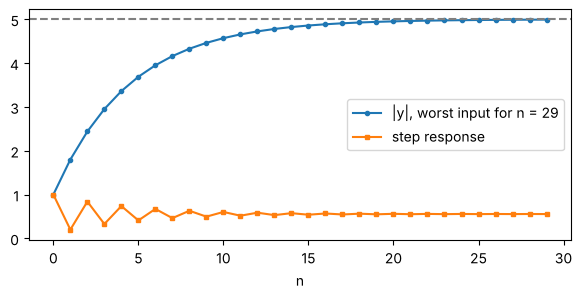

In [3]:
def recursion(a, x):
    y, prev = np.zeros(len(x)), 0.0
    for i, xi in enumerate(x):
        prev = a * prev + xi
        y[i] = prev
    return y

a, Nn = -0.8, 30
worst = np.array([np.sign(a ** (Nn - 1 - m)) for m in range(Nn)])   # x[m] = sign(a^(N-1-m))
y_worst = recursion(a, worst)
y_step = recursion(a, np.ones(Nn))
print(f"bound 1/(1-|a|) = {1 / (1 - abs(a)):.4f}")
print(f"worst input: |y[{Nn - 1}]| = {abs(y_worst[-1]):.4f}")
print(f"step: final value = {y_step[-1]:.4f} (1/(1 - a) = {1 / (1 - a):.4f})")
plt.figure(figsize=(7, 3))
plt.plot(np.abs(y_worst), "o-", ms=3, label="|y|, worst input for n = 29")
plt.plot(y_step, "s-", ms=3, label="step response")
plt.axhline(1 / (1 - abs(a)), ls="--", color="0.5")
plt.xlabel("n"); plt.legend(); plt.show()

## Part 3 — Distortion by FFT (guided exercise)

**Predict first:** for $y = 10x + 0.5x^2 - 0.2x^3$, how much do HD2 and HD3 change when the input amplitude rises from 0.1 V to 0.3 V? Then run the cell. The FFT uses a whole number of cycles in the record, so every component falls exactly on one bin.

In [4]:
def amp(x):
    return 10 * x + 0.5 * x ** 2 - 0.2 * x ** 3

def harmonics(A, M=4096, cycles=8):
    t = np.arange(M) / M
    Y = np.fft.rfft(amp(A * np.cos(2 * np.pi * cycles * t))) / M * 2
    f1, h2, h3 = abs(Y[cycles]), abs(Y[2 * cycles]), abs(Y[3 * cycles])
    return 20 * np.log10(h2 / f1), 20 * np.log10(h3 / f1)

levels = [0.01, 0.03, 0.1, 0.3]
table = {A: harmonics(A) for A in levels}
for A, (d2, d3) in table.items():
    print(f"A = {A:5.2f} V: HD2 = {d2:7.2f} dB, HD3 = {d3:7.2f} dB")
print(f"slope from 0.01 V to 0.1 V: HD2 {table[0.1][0] - table[0.01][0]:.2f} dB/decade, "
      f"HD3 {table[0.1][1] - table[0.01][1]:.2f} dB/decade")

A =  0.01 V: HD2 =  -72.04 dB, HD3 = -126.02 dB
A =  0.03 V: HD2 =  -62.50 dB, HD3 = -106.94 dB
A =  0.10 V: HD2 =  -52.04 dB, HD3 =  -86.02 dB
A =  0.30 V: HD2 =  -42.49 dB, HD3 =  -66.92 dB
slope from 0.01 V to 0.1 V: HD2 20.00 dB/decade, HD3 40.00 dB/decade


## Part 4 — Inverse systems, exact and practical

The channel $y[n] = x[n] + b\,x[n - 1]$ is inverted by the recursion $w[n] = y[n] - b\,w[n - 1]$. Add 1 mV rms of receiver noise to the received samples and compare $b = 0.5$ with $b = 2$. Then build the stable noncausal inverse for $b = 2$, truncate it to $K$ taps and delay it by $K$ samples so that it is causal.

In [5]:
x = rng.choice([-1.0, 1.0], size=40)                 # a random binary data sequence
for b in (0.5, 2.0):
    y = x + b * delay(x, 1)
    yq = y + rng.normal(0, 1e-3, size=y.size)            # 1 mV rms of receiver noise
    w = recursion(-b, yq)
    print(f"b = {b}: largest recovery error over 40 samples = {np.max(np.abs(w - x)):.3g} V")

# error growth for b = 2: first sample at which a 1 mV error exceeds 1 V
n_cross = next(n for n in range(100) if 1e-3 * 2.0 ** n > 1.0)
print("1 mV error exceeds 1 V after", n_cross, "samples")

# truncated, delayed noncausal inverse for b = 2: g[-k] = 0.5 (-0.5)^(k-1), k = 1..K
K = 8
g = np.array([0.5 * (-0.5) ** (k - 1) for k in range(K, 0, -1)])    # taps for k = K..1, i.e. a delay of K
h = np.array([1.0, 2.0])
cascade = np.convolve(g, h)
print("channel followed by the truncated inverse:", np.round(cascade, 5))
main = np.argmax(np.abs(cascade))
residual = np.max(np.abs(np.delete(cascade, main)))
print(f"main tap at delay {main} with value {cascade[main]:.4f}; largest residual {residual:.4f}")

b = 0.5: largest recovery error over 40 samples = 0.0019 V
b = 2.0: largest recovery error over 40 samples = 6.1e+07 V
1 mV error exceeds 1 V after 10 samples
channel followed by the truncated inverse: [-0.00391  0.       0.       0.       0.       0.       0.       0.
  1.     ]
main tap at delay 8 with value 1.0000; largest residual 0.0039


**What to take away.** A property is a statement about all inputs, so a tester can refute it but only gather evidence for it. The worst input for a stable recursion is easy to construct and can be far worse than a step. Distortion follows the polynomial's powers exactly: 20 dB per decade for HD2 and 40 for HD3. And an exact inverse can be useless when it is unstable, while an approximate, delayed inverse works: the residual falls by half for each extra tap, at the cost of one more sample of latency.